# 1. Machine learning Fundamentals


## What is Machine Learning?
Machine Learning(ML) is a branch of Artificial Intelligence that enables computers to learn from data and make predictions or decisions without being explicitly programmed for every task. It helps identify patterns, automate tasks and make predictions on new data based on patterns learned from historical data. 
Similarly, ShopSmart Retail Ltd. can use historical retail data to predict the total value of an order and estimate whether an order is likely to be returned. These predictions could support sales planning, inventory decisions, and customer service.
## Types of Machine Learning
There are three main types of Machine Learning:
* **Supervised learning** - The model learns from labelled data, where the correct outcome is already known.
* **Unsupervised learning** - The model identifies patterns or groups in data without being given predefined outcome labels.
* **Reinforcement learning** - An agent learns which actions to take by interacting with an environment and receiving rewards or penalties.
## Supervised Learning
Supervised learning uses historical data containing input variables also called **features** and a known outcome called the **target variable**. During training, the model learns relationships between the features and the target so it can predict outcomes for new observations.

There are two main categories of supervised learning:
1. **Regression** - Predicts continuous values, such as house prices or product sales. It learns the relationship between input features and a numerical target variable.

2. **Classification** - Predicts categorical outputs, meaning it assigns data into predefined classes like spam/non-spam emails or disease risk categories
## Unsupervised Learning
Unsupervised learning works with data that does not have a predefined target variable. Rather than predicting a known outcome, the model attempts to discover patterns, similarities or structures in the data. It’s mainly used for clustering, dimensionality reduction and data visualization.
## Reinforcement Learning
Reinforcement learning involves an agent that interacts with an environment, takes actions and receives rewards or penalties based on the results. Over time, the agent learns a strategy intended to maximise cumulative reward. Its main components are the agent, environment, actions, rewards and policy.
## Regression vs Classification
They are both supervised learning techniques but they predict different types of outcomes.

|Feature                   |Regression                       |Classification                       |
| -------------------------| --------------------------------| ------------------------------------|
|Purpose                   |Predict a numerical value        |Predict a category                   |
|Output                    |A continous numerical prediction |A class or class probability         |
|ShopSmart example         |Predict Order_Total              |Predict Return_Flag                  |
|Common evaluation metrics |MAE, RMSE, R²                    |Accuracy, Precision, Recall, F1 Score|

## Machine Learning Workflow
1. **Defining the business problem:** Identify the problem you want to solve and the outcome the business wants to predict.
2. **Collect and understand the data:** Load the available datasets and examine their columns, data types, quality and relationships.
3. **Prepare the data:** Handle missing values, remove duplicates where appropriate, combine relevant datasets and correct data quality issues.
4. **Perform feature engineering:** Select or create useful input variables for the model.
5. **Split the data:** Divide the data into training and testing sets to assess how well the model generalises to unseen observations.
6. **Select and train a model:** Choose an appropriate algorithm and train it using the training data.
7. **Evaluate the model:** Use suitable metrics to measure predictive performance and identify weaknesses.
8. **Improve the model:** Where appropriate, refine features, adjust model settings and compare alternative approaches.
9. **Save and use the model:** Save the trained model so it can be loaded later to make predictions.
10. **Monitor Perfomance:** If the model is used over time, monitor its accuracy and check whether changes in the data affect its performance.

# 2. Data Preparation

## 2.1 Loading the Datasets

The first step is to load the ShopSmart datasets into Pandas so that we can inspect their structure, data types, and data quality before combining them.

In [47]:
import pandas as pd
from pathlib import Path

# Define the folder containing the datasets
DATA_DIR = Path("data")

# Loading the nine business datasets
datasets = {
    "customers": "ALA_ShopSmart_Customers.csv",
    "employees": "ShopSmart_Employees.csv",
    "inventory": "ShopSmart_Inventory.csv",
    "orders": "ShopSmart_Orders.csv",
    "order_items": "ShopSmart_Order_Items.csv",
    "products": "ShopSmart_Products.csv",
    "returns": "ShopSmart_Returns.csv",
    "stores": "ShopSmart_Stores.csv",
    "suppliers": "ShopSmart_Suppliers.csv"
}

# Reading each CSV file into a Pandas DataFrame
for name, filename in datasets.copy().items():
    datasets[name] = pd.read_csv(DATA_DIR / filename)

# Loading the data dictionary separately
data_dictionary = pd.read_csv(
    DATA_DIR / "ShopSmart_Data_Dictionary.csv"
)

print("All nine business datasets have been loaded successfully.")

All nine business datasets have been loaded successfully.


In [48]:
#Looping through the dataframes to get the no. of rows and columns
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows and {df.shape[1]} columns")

customers: 5000 rows and 11 columns
employees: 125 rows and 6 columns
inventory: 500 rows and 6 columns
orders: 50000 rows and 12 columns
order_items: 50000 rows and 7 columns
products: 500 rows and 7 columns
returns: 2500 rows and 5 columns
stores: 25 rows and 6 columns
suppliers: 489 rows and 6 columns


## 2.2 Merging into one Master Dataset

Tackling our first target variable `Order_Total`

In [49]:
#Inspecting Table Relationships
#Inspecting a few records from each table
orders = datasets['orders']
order_items = datasets['order_items']
print('ORDERS - first 5 rows')
display(orders.head())

print('ORDER_ITEMS - first 5 rows')
display(order_items.head())

#Checking key uniqueness
print('\nKey checks')
print('Unique Order_IDs in orders:', orders['Order_ID'].nunique())
print('Unique Order_IDs in order_items:', order_items['Order_ID'].nunique())

print('Unique Order_ID + Product_ID pairs in orders:',
orders[['Order_ID', 'Product_ID']].drop_duplicates().shape[0])

print('Unique Order_ID + Product_ID pairs in order_items',
order_items[['Order_ID', 'Product_ID']].drop_duplicates().shape[0])

ORDERS - first 5 rows


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status
0,ORD000001,CUST04572,PROD0244,STR005,7/19/2025,1,77989,10,3833,Card,Online,Completed
1,ORD000002,CUST04064,PROD0432,STR010,3/15/2025,3,11240,5,2872,Card,In-Store,Cancelled
2,ORD000003,CUST03435,PROD0052,STR004,10/1/2025,2,23595,20,922,Card,Online,Pending
3,ORD000004,CUST03536,PROD0051,STR023,7/15/2025,4,69922,5,911,Transfer,Online,Completed
4,ORD000005,CUST03676,PROD0356,STR021,3/28/2025,5,53344,0,1740,Card,Online,Cancelled


ORDER_ITEMS - first 5 rows


,Order_Item_ID,Order_ID,Product_ID,Quantity,Unit_Price,Discount,Line_Total
0,OI000001,ORD000001,PROD0244,1,77989,10,77979
1,OI000002,ORD000002,PROD0432,3,11240,5,33715
2,OI000003,ORD000003,PROD0052,2,23595,20,47170
3,OI000004,ORD000004,PROD0051,4,69922,5,279683
4,OI000005,ORD000005,PROD0356,5,53344,0,266720



Key checks
Unique Order_IDs in orders: 50000
Unique Order_IDs in order_items: 50000
Unique Order_ID + Product_ID pairs in orders: 50000
Unique Order_ID + Product_ID pairs in order_items 50000


In [50]:
order_keys = set(zip(orders['Order_ID'],orders['Product_ID']))
order_items_keys = set(zip(order_items['Order_ID'], order_items['Product_ID']))

print('Pairs in orders but not order_items:', len(order_keys - order_items_keys))
print('Pairs in order_items but not in orders:', len(order_items_keys - order_keys))

Pairs in orders but not order_items: 0
Pairs in order_items but not in orders: 0


In [51]:
#Combining orders and order_items
orders_items = orders.merge(order_items, on=['Order_ID', 'Product_ID'],
how='inner',
suffixes=('_order', '_item'),
validate='one_to_one'
)
print('Merged dataset shape:',
orders_items.shape)
display(orders_items.head())

Merged dataset shape: (50000, 17)


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity_order,Unit_Price_order,Discount_order,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status,Order_Item_ID,Quantity_item,Unit_Price_item,Discount_item,Line_Total
0,ORD000001,CUST04572,PROD0244,STR005,7/19/2025,1,77989,10,3833,Card,Online,Completed,OI000001,1,77989,10,77979
1,ORD000002,CUST04064,PROD0432,STR010,3/15/2025,3,11240,5,2872,Card,In-Store,Cancelled,OI000002,3,11240,5,33715
2,ORD000003,CUST03435,PROD0052,STR004,10/1/2025,2,23595,20,922,Card,Online,Pending,OI000003,2,23595,20,47170
3,ORD000004,CUST03536,PROD0051,STR023,7/15/2025,4,69922,5,911,Transfer,Online,Completed,OI000004,4,69922,5,279683
4,ORD000005,CUST03676,PROD0356,STR021,3/28/2025,5,53344,0,1740,Card,Online,Cancelled,OI000005,5,53344,0,266720


In [52]:
display(
    orders_items[
        [
            'Order_ID',
            'Product_ID',
            'Quantity_order',
            'Unit_Price_order',
            'Discount_order',
            'Shipping_Cost',
            'Line_Total'
        ]
    ].head(10)
)

,Order_ID,Product_ID,Quantity_order,Unit_Price_order,Discount_order,Shipping_Cost,Line_Total
0,ORD000001,PROD0244,1,77989,10,3833,77979
1,ORD000002,PROD0432,3,11240,5,2872,33715
2,ORD000003,PROD0052,2,23595,20,922,47170
3,ORD000004,PROD0051,4,69922,5,911,279683
4,ORD000005,PROD0356,5,53344,0,1740,266720
5,ORD000006,PROD0458,3,31991,0,3452,95973
6,ORD000007,PROD0174,5,5086,20,3064,25410
7,ORD000008,PROD0171,4,32902,0,4279,131608
8,ORD000009,PROD0336,2,99649,5,1266,199293
9,ORD000010,PROD0381,4,75235,0,3693,300940


From the output above, we can confirm that:

**Line Total = (Quantity × Unit Price) − Discount**

However, our assignment requires us to predict the total order value. For this project, we will define it as:

**Order_Total = Line_Total + Shipping_Cost**

Assuming `Shipping_Cost` is the shipping charge for each order.

We therefore need to create a new target variable column, `Order_Total`, to store the calculated total for each order.

In [53]:
orders_items['Order_Total'] = (orders_items['Line_Total'] + orders_items['Shipping_Cost'])

display(orders_items[
    [
        'Order_ID',
        'Line_Total',
        'Shipping_Cost',
        'Order_Total']].head(10))

,Order_ID,Line_Total,Shipping_Cost,Order_Total
0,ORD000001,77979,3833,81812
1,ORD000002,33715,2872,36587
2,ORD000003,47170,922,48092
3,ORD000004,279683,911,280594
4,ORD000005,266720,1740,268460
5,ORD000006,95973,3452,99425
6,ORD000007,25410,3064,28474
7,ORD000008,131608,4279,135887
8,ORD000009,199293,1266,200559
9,ORD000010,300940,3693,304633


In [54]:
print('Order_Total created:', 'Order_Total' in orders_items.columns)
print('Missing Order_Total values:', orders_items['Order_Total'].isna().sum())

Order_Total created: True
Missing Order_Total values: 0


Tackling our second target variable `Return_Flag`

In [55]:
returns = datasets['returns']

print('returns shape:', returns.shape)
print('\nreturns columns:')
print(returns.columns.tolist())
display(returns.head(10))

returns shape: (2500, 5)

returns columns:
['Return_ID', 'Order_ID', 'Return_Date', 'Return_Reason', 'Refund_Amount']


,Return_ID,Order_ID,Return_Date,Return_Reason,Refund_Amount
0,RET00001,ORD035655,10/8/2025,Wrong Item,12433
1,RET00002,ORD037628,12/17/2025,Damaged,41722
2,RET00003,ORD046331,1/11/2025,Wrong Item,46937
3,RET00004,ORD019527,2/6/2025,Wrong Item,9943
4,RET00005,ORD022292,12/17/2025,Wrong Item,10350
5,RET00006,ORD002709,1/11/2025,Damaged,40902
6,RET00007,ORD045869,6/9/2025,Wrong Item,41604
7,RET00008,ORD002100,7/12/2025,Late Delivery,49944
8,RET00009,ORD020108,5/15/2025,Customer Changed Mind,13478
9,RET00010,ORD029115,11/21/2025,Damaged,8486


In [56]:
print('Total return records:', len(returns))

#Checking if the keys are unique
print('Unique Order_IDs in returns:', returns['Order_ID'].nunique())
print('Unique Return_IDs in returns:', returns['Return_ID'].nunique())
print('Duplicate Order_IDs in returns:', returns['Order_ID'].duplicated().sum())

Total return records: 2500
Unique Order_IDs in returns: 2442
Unique Return_IDs in returns: 2500
Duplicate Order_IDs in returns: 58


In [57]:
return_counts = returns['Order_ID'].value_counts()

print('Orders with more than one return record:',
(return_counts > 1).sum())

print('Examples of repeated Order_IDs:')
display(return_counts[return_counts > 1].head(10))

Orders with more than one return record: 56
Examples of repeated Order_IDs:


Order_ID
ORD005557    3
ORD035519    3
ORD037628    2
ORD029115    2
ORD049538    2
ORD029201    2
ORD033946    2
ORD040218    2
ORD017399    2
ORD040335    2
Name: count, dtype: int64

In [58]:
#Getting the unique order IDs tha appear in Returns
returns_order_ids = returns['Order_ID'].unique()

#Creating the target variable
orders_items['Return_Flag'] = orders_items['Order_ID'].isin(returns_order_ids).astype(int)

print(orders_items['Return_Flag'].value_counts())

Return_Flag
0    47558
1     2442
Name: count, dtype: int64


In [59]:
#Checking if the Order_IDs in the returns dataset matches an order in our merged dataset
print('Returns records with matching orders:',
returns['Order_ID'].isin(orders_items['Order_ID']).sum())

print('Returns records without matching orders:',
(~returns['Order_ID'].isin(orders_items['Order_ID'])).sum())

Returns records with matching orders: 2500
Returns records without matching orders: 0


Both target variables columns have been created successfully 

In [60]:
#Checking the columns in all the datasets
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print('Columns:', df.columns.tolist())


CUSTOMERS
Columns: ['Customer_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment']

EMPLOYEES
Columns: ['Employee_ID', 'Employee_Name', 'Role', 'Store_ID', 'Hire_Date', 'Monthly_Salary']

INVENTORY
Columns: ['Inventory_ID', 'Product_ID', 'Store_ID', 'Stock_On_Hand', 'Reorder_Level', 'Last_Restock_Date']

ORDERS
Columns: ['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Order_Date', 'Quantity', 'Unit_Price', 'Discount', 'Shipping_Cost', 'Payment_Method', 'Sales_Channel', 'Order_Status']

ORDER_ITEMS
Columns: ['Order_Item_ID', 'Order_ID', 'Product_ID', 'Quantity', 'Unit_Price', 'Discount', 'Line_Total']

PRODUCTS
Columns: ['Product_ID', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Cost_Price', 'Selling_Price']

RETURNS
Columns: ['Return_ID', 'Order_ID', 'Return_Date', 'Return_Reason', 'Refund_Amount']

STORES
Columns: ['Store_ID', 'Store_Name', 'Region', 'State', 'City', 'Opening_Date']

SUPPLIERS
Colu

In [61]:
#Checking for missing and duplicated values in each dataset
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print('Missing values:', df.isna().sum().sum())
    print('Duplicated values:', df.duplicated().sum())


CUSTOMERS
Missing values: 0
Duplicated values: 0

EMPLOYEES
Missing values: 0
Duplicated values: 0

INVENTORY
Missing values: 0
Duplicated values: 0

ORDERS
Missing values: 0
Duplicated values: 0

ORDER_ITEMS
Missing values: 0
Duplicated values: 0

PRODUCTS
Missing values: 0
Duplicated values: 0

RETURNS
Missing values: 0
Duplicated values: 0

STORES
Missing values: 0
Duplicated values: 0

SUPPLIERS
Missing values: 0
Duplicated values: 0


In [62]:
#Checking whether the key IDs are unique in each table
# Check whether the key IDs are unique in each table

print('Unique Customer_IDs:', datasets['customers']['Customer_ID'].nunique())
print('Total customer rows:', len(datasets['customers']))

print('\nUnique Product_IDs:', datasets['products']['Product_ID'].nunique())
print('Total product rows:', len(datasets['products']))

print('\nUnique Store_IDs:', datasets['stores']['Store_ID'].nunique())
print('Total store rows:', len(datasets['stores']))

Unique Customer_IDs: 5000
Total customer rows: 5000

Unique Product_IDs: 500
Total product rows: 500

Unique Store_IDs: 25
Total store rows: 25


In [63]:
# Checking whether order IDs match the customer, product, and store tables

print(
    "Orders with unmatched customers:",
    (~orders_items["Customer_ID"].isin(
        datasets["customers"]["Customer_ID"]
    )).sum())

print(
    "Orders with unmatched products:",
    (~orders_items["Product_ID"].isin(
        datasets["products"]["Product_ID"]
    )).sum())

print(
    "Orders with unmatched stores:",
    (~orders_items["Store_ID"].isin(
        datasets["stores"]["Store_ID"]
    )).sum())

Orders with unmatched customers: 0
Orders with unmatched products: 0
Orders with unmatched stores: 0


In [64]:
# Merging customer information into the orders dataset
master_df = orders_items.merge(
    datasets["customers"],
    on="Customer_ID",
    how="left",
    validate="many_to_one"
)

print("Shape before merge:", orders_items.shape)
print("Shape after customer merge:", master_df.shape)

Shape before merge: (50000, 19)
Shape after customer merge: (50000, 29)


In [65]:
# Merging product information into the master dataset
master_df = master_df.merge(
    datasets["products"],
    on="Product_ID",
    how="left",
    validate="many_to_one",
    suffixes=("", "_product")
)

print("Shape after product merge:", master_df.shape)

Shape after product merge: (50000, 35)


In [66]:
# Merging store information into the master dataset
master_df = master_df.merge(
    datasets["stores"],
    on="Store_ID",
    how="left",
    validate="many_to_one",
    suffixes=("", "_store")
)

print("Shape after store merge:", master_df.shape)

Shape after store merge: (50000, 40)


In [67]:
#Printing the master dataset
print("Master dataset columns:")
print(master_df.columns.tolist())

print("\nMaster dataset shape:", master_df.shape)

display(master_df.head())

Master dataset columns:
['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Order_Date', 'Quantity_order', 'Unit_Price_order', 'Discount_order', 'Shipping_Cost', 'Payment_Method', 'Sales_Channel', 'Order_Status', 'Order_Item_ID', 'Quantity_item', 'Unit_Price_item', 'Discount_item', 'Line_Total', 'Order_Total', 'Return_Flag', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Cost_Price', 'Selling_Price', 'Store_Name', 'Region', 'State_store', 'City_store', 'Opening_Date']

Master dataset shape: (50000, 40)


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity_order,Unit_Price_order,Discount_order,Shipping_Cost,Payment_Method,...,Category,Sub_Category,Brand,Cost_Price,Selling_Price,Store_Name,Region,State_store,City_store,Opening_Date
0,ORD000001,CUST04572,PROD0244,STR005,7/19/2025,1,77989,10,3833,Card,...,Groceries,General,Olson-Vance,48631,76491.21,ShopSmart Enugu,South,Enugu,Enugu,5/30/2020
1,ORD000002,CUST04064,PROD0432,STR010,3/15/2025,3,11240,5,2872,Card,...,Home,General,Jones-Vaughn,3269,4909.31,ShopSmart Abuja,North,Abuja,Abuja,10/27/2020
2,ORD000003,CUST03435,PROD0052,STR004,10/1/2025,2,23595,20,922,Card,...,Electronics,General,"Martinez, Rice and Perry",31027,39852.54,ShopSmart Asaba,South,Delta,Asaba,4/30/2020
3,ORD000004,CUST03536,PROD0051,STR023,7/15/2025,4,69922,5,911,Transfer,...,Home,General,"Peterson, Berry and Cook",29214,50320.76,ShopSmart Abuja,South,Abuja,Abuja,11/21/2021
4,ORD000005,CUST03676,PROD0356,STR021,3/28/2025,5,53344,0,1740,Card,...,Electronics,General,"Sanders, Flores and Lopez",35224,44115.99,ShopSmart Lagos,West,Lagos,Lagos,9/22/2021


In [68]:
# Checking whether inventory has unique inventory IDs
print("Inventory rows:", len(datasets["inventory"]))
print(
    "Unique Inventory_IDs:",
    datasets["inventory"]["Inventory_ID"].nunique()
)

# Checking whether inventory refers to existing products and stores
print(
    "Inventory records with unmatched products:",
    (~datasets["inventory"]["Product_ID"].isin(
        datasets["products"]["Product_ID"]
    )).sum()
)

print(
    "Inventory records with unmatched stores:",
    (~datasets["inventory"]["Store_ID"].isin(
        datasets["stores"]["Store_ID"]
    )).sum()
)

Inventory rows: 500
Unique Inventory_IDs: 500
Inventory records with unmatched products: 0
Inventory records with unmatched stores: 0


In [69]:
inventory = datasets["inventory"]

print(
    "Unique product-store combinations:",
    inventory[["Product_ID", "Store_ID"]].drop_duplicates().shape[0]
)

print(
    "Total inventory records:",
    len(inventory)
)

Unique product-store combinations: 500
Total inventory records: 500


In [70]:
#Inspecting the employees dataset
employees = datasets["employees"]

print("Employee rows:", len(employees))

print(
    "Unique Employee_IDs:",
    employees["Employee_ID"].nunique()
)

print(
    "Employees with unmatched stores:",
    (~employees["Store_ID"].isin(
        datasets["stores"]["Store_ID"]
    )).sum()
)

Employee rows: 125
Unique Employee_IDs: 125
Employees with unmatched stores: 0


In [71]:
#Inspecting the suppliers dataset
suppliers = datasets["suppliers"]
products = datasets["products"]

print("Supplier rows:", len(suppliers))

print(
    "Unique Supplier_IDs:",
    suppliers["Supplier_ID"].nunique()
)

print("\nSupplier columns:")
print(suppliers.columns.tolist())

print("\nProduct columns:")
print(products.columns.tolist())

Supplier rows: 489
Unique Supplier_IDs: 489

Supplier columns:
['Supplier_ID', 'Supplier_Name', 'Email', 'Phone', 'City', 'Country']

Product columns:
['Product_ID', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Cost_Price', 'Selling_Price']


#### 1. Datasets Not Included in the Master Dataset

Although all nine business datasets were loaded and inspected, the master dataset currently combines the orders, order items, customers, products, and stores datasets. The remaining three datasets — employees, inventory, and suppliers — have been kept separate for the following reasons:

- **Employees:** The dataset contains employee information such as roles and monthly salaries, and employees are linked to stores through `Store_ID`. However, the orders dataset does not contain an `Employee_ID` that would allow us to associate individual orders with specific employees. Merging employee information using only `Store_ID` could introduce multiple rows per order or assign employee details in a misleading way.

- **Inventory:** The dataset contains stock levels and restocking information for individual product–store combinations. Although every inventory record has a matching product and store, inventory represents stock information rather than an individual transaction. It has therefore been kept separate to avoid introducing unnecessary complexity or unintentionally multiplying order rows.

- **Suppliers:** The dataset contains supplier details, including names, contact information, and locations. However, the products dataset does not contain a `Supplier_ID`, and the suppliers dataset does not contain a `Product_ID`. Without a linking key, the relationship between suppliers and products cannot be established reliably from the available columns.

The returns dataset was used to create the `Return_Flag` target variable. This approach identifies whether an order appears in the returns records without merging multiple return records into the master dataset and potentially duplicating orders.

#### 2. Removal of Redundant Columns

During the initial merge of the orders and order items datasets, some columns appeared twice because both datasets contained the same information. These columns were renamed with suffixes to distinguish their sources.

Earlier validation checks confirmed that the following pairs contain identical values:

- `Quantity_order` and `Quantity_item`
- `Unit_Price_order` and `Unit_Price_item`
- `Discount_order` and `Discount_item`

Since the values in each pair match, the `_item` versions they provide no additional information therefore, they will be removed, while the `_order` versions are retained.

This makes the master dataset easier to interpret, and prevents unnecessary duplicate features from being carried into the subsequent data preparation and modelling stages.

In [72]:
master_df = master_df.drop(
    columns=[
        "Quantity_item",
        "Unit_Price_item",
        "Discount_item"
    ])

print("Master dataset shape:", master_df.shape)

Master dataset shape: (50000, 37)


## 2.3 Converting date columns

In [73]:
#Checking if the date columns are in datetime format
date_columns = [
    "Order_Date",
    "Registration_Date",
    "Opening_Date"
]

print(master_df[date_columns].dtypes)

Order_Date           str
Registration_Date    str
Opening_Date         str
dtype: object


In [74]:
#They are stored as texts
#Converting them into pandas datetime format
for column in date_columns:
    master_df[column] = pd.to_datetime(
        master_df[column],
        errors="coerce"
    )

print(master_df[date_columns].dtypes)

Order_Date           datetime64[us]
Registration_Date    datetime64[us]
Opening_Date         datetime64[us]
dtype: object


In [75]:
#Checking if converting to datetime introduced missing values
print("Missing dates after conversion:")

print(master_df[date_columns].isna().sum())

Missing dates after conversion:
Order_Date           0
Registration_Date    0
Opening_Date         0
dtype: int64


### Date Column Conversion

The `Order_Date`, `Registration_Date`, and `Opening_Date` columns were initially stored as strings. I converted them to pandas datetime types using `pd.to_datetime()`.

After conversion, I checked for missing dates. All three columns contained zero missing values, confirming that the conversion was successful and no invalid dates were detected.

Converting these columns allows date-based operations and makes it possible to derive useful features, such as the order month or year, if required for the analysis.

## 2.4 Handling Missing Values

In [76]:
# Checking missing values in the master dataset
missing_values = master_df.isnull().sum()

print("Total missing values:", missing_values.sum())

# Displaying columns that contain missing values, if any
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


### Handling Missing Values

After merging the orders, order items, customers, products, and stores datasets, I checked the master dataset for missing values using `isnull().sum()`.

The check returned **zero missing values across all 37 columns**. Therefore, no imputation or deletion was necessary at this stage. The master dataset was retained without modifications for missing-value handling.

Although the original datasets also contained no missing values, checking the merged dataset was important to verify that the merging process had not introduced any missing values.

## 2.5 Removing Duplicates

In [77]:
# Count exact duplicate rows in the master dataset
duplicate_count = master_df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


### Removing Duplicate Records

After checking for missing values, I checked the master dataset for duplicate rows using `master_df.duplicated().sum()`.

The result was zero, indicating that there are no exact duplicate rows in the master dataset. Therefore, no rows needed to be removed during this step and the dataset was retained unchanged.

This check helps ensure that identical records do not unnecessarily affect the subsequent analysis and model training.

## 2.6 Saving the dataset

In [78]:
#Saving the master dataset
from pathlib import Path

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

master_df.to_csv(
    DATA_DIR / "master_dataset.csv",
    index=False
)

print("Master dataset saved successfully.")
print("Shape:", master_df.shape)
print("File:", DATA_DIR / "master_dataset.csv")

Master dataset saved successfully.
Shape: (50000, 37)
File: data\master_dataset.csv


## 2.7 Selecting features and Splitting the data

### Preprocessing Strategy

Although the assignment lists categorical encoding and numerical scaling before the train/test split, encoding and numerical scaling before splitting the data may lead to data leakage i.e., the model being exposed to the test data.

The master dataset will first be divided into training and testing sets. The categorical encoder and numerical scaler will then be fitted using only the training data. The fitted transformations will subsequently be applied to both sets, including the unseen test data.

This prevents information from the test set from influencing the preprocessing process and provides a more reliable evaluation of model performance.

I will use relevant customer, product, geographical, and order-related features as predictors. Target variables and features that could cause data leakage will be excluded from the appropriate predictor sets.

In [79]:
#Checking categorical columns
categorical_columns = master_df.select_dtypes(
    include=["str", "category"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))
print("\nCategorical columns:")
print(categorical_columns)

Number of categorical columns: 24

Categorical columns:
['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Payment_Method', 'Sales_Channel', 'Order_Status', 'Order_Item_ID', 'First_Name', 'Last_Name', 'Gender', 'Email', 'Phone', 'City', 'State', 'Customer_Segment', 'Product_Name', 'Category', 'Sub_Category', 'Brand', 'Store_Name', 'Region', 'State_store', 'City_store']


In [80]:
#Checking numerical columns
numerical_columns = master_df.select_dtypes(
    include="number"
).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))
print("\nNumerical columns:")
print(numerical_columns)

Number of numerical columns: 10

Numerical columns:
['Quantity_order', 'Unit_Price_order', 'Discount_order', 'Shipping_Cost', 'Line_Total', 'Order_Total', 'Return_Flag', 'Age', 'Cost_Price', 'Selling_Price']


In [81]:
#Reviewing categorical columns before encoding
categorical_features = [
    "Gender",
    "Customer_Segment",
    "Payment_Method",
    "Sales_Channel",
    "Order_Status",
    "Category",
    "Sub_Category",
    "Brand",
    "Region"
]

for column in categorical_features:
    if column in master_df.columns:
        print(f"\n{column}:")
        print(master_df[column].value_counts().head(10))


Gender:
Gender
Male      25729
Female    24271
Name: count, dtype: int64

Customer_Segment:
Customer_Segment
Gold      16961
Silver    16773
Bronze    16266
Name: count, dtype: int64

Payment_Method:
Payment_Method
Card        16741
Cash        16693
Transfer    16566
Name: count, dtype: int64

Sales_Channel:
Sales_Channel
In-Store    25018
Online      24982
Name: count, dtype: int64

Order_Status:
Order_Status
Cancelled    16861
Pending      16610
Completed    16529
Name: count, dtype: int64

Category:
Category
Beauty         11809
Groceries      10352
Electronics     9969
Fashion         9260
Home            8610
Name: count, dtype: int64

Sub_Category:
Sub_Category
General    50000
Name: count, dtype: int64

Brand:
Brand
Williams Group       213
Martinez Ltd         211
Thomas Ltd           211
Myers and Sons       208
Dyer LLC             207
Smith LLC            206
Jones Group          204
Garcia PLC           203
Matthews and Sons    195
Rosales PLC          190
Name: count, dt

In [82]:
#Checking for unique categories among the categorical columns
for column in categorical_features:
    if column in master_df.columns:
        print(
            f"{column}: "
            f"{master_df[column].nunique()} unique categories"
        )

Gender: 2 unique categories
Customer_Segment: 3 unique categories
Payment_Method: 3 unique categories
Sales_Channel: 2 unique categories
Order_Status: 3 unique categories
Category: 5 unique categories
Sub_Category: 1 unique categories
Brand: 489 unique categories
Region: 4 unique categories


In [83]:
# Categorical predictors selected for both models
categorical_features = [
    "Customer_Segment",
    "Payment_Method",
    "Sales_Channel",
    "Category",
    "Region"
]

# Numerical predictors for the Order_Total model
regression_numeric_features = [
    "Quantity_order",
    "Unit_Price_order",
    "Discount_order",
    "Shipping_Cost"
]

# Numerical predictors for the Return_Flag model
classification_numeric_features = [
    "Quantity_order",
    "Unit_Price_order",
    "Discount_order",
    "Shipping_Cost"
]

# Defining predictors (X) and targets (y)
#Regression
#Predictors(X)
X_regression = master_df[
    categorical_features + regression_numeric_features
].copy()

#Target (y)
y_regression = master_df["Order_Total"].copy()

#Classification
#Predictors(X)
X_classification = master_df[
    categorical_features + classification_numeric_features
].copy()

#target(y)
y_classification = master_df["Return_Flag"].copy()

print("Regression predictors:", X_regression.shape)
print("Regression target:", y_regression.shape)

print("\nClassification predictors:", X_classification.shape)
print("Classification target:", y_classification.shape)

Regression predictors: (50000, 9)
Regression target: (50000,)

Classification predictors: (50000, 9)
Classification target: (50000,)


In [84]:
print("Order_Total summary:")
display(master_df["Order_Total"].describe())

print("\nReturn_Flag distribution:")
print(master_df["Return_Flag"].value_counts())

print("\nReturn_Flag proportions:")
print(master_df["Return_Flag"].value_counts(normalize=True).round(3))

Order_Total summary:


count     50000.000000
mean     154252.710320
std      119097.398905
min        1753.000000
25%       58692.750000
50%      121572.000000
75%      228533.250000
max      504460.000000
Name: Order_Total, dtype: float64


Return_Flag distribution:
Return_Flag
0    47558
1     2442
Name: count, dtype: int64

Return_Flag proportions:
Return_Flag
0    0.951
1    0.049
Name: proportion, dtype: float64


In [85]:

#Creating a shared train/test split
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    master_df,
    test_size=0.2,
    random_state=42,
    stratify=master_df["Return_Flag"]
)

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

print("\nReturn distribution in training data:")
print(train_df["Return_Flag"].value_counts(normalize=True).round(3))

print("\nReturn distribution in testing data:")
print(test_df["Return_Flag"].value_counts(normalize=True).round(3))

Training dataset: (40000, 37)
Testing dataset: (10000, 37)

Return distribution in training data:
Return_Flag
0    0.951
1    0.049
Name: proportion, dtype: float64

Return distribution in testing data:
Return_Flag
0    0.951
1    0.049
Name: proportion, dtype: float64


In [86]:
# Features used by both models
feature_columns = (
    categorical_features + regression_numeric_features
)

# Training predictors
X_train = train_df[feature_columns].copy()

# Testing predictors
X_test = test_df[feature_columns].copy()

# Regression target
y_reg_train_final = train_df["Order_Total"].copy()
y_reg_test_final = test_df["Order_Total"].copy()

# Classification target
y_clf_train_final = train_df["Return_Flag"].copy()
y_clf_test_final = test_df["Return_Flag"].copy()

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)
print("Regression training target:", y_reg_train_final.shape)
print("Classification training target:", y_clf_train_final.shape)

Training predictors: (40000, 9)
Testing predictors: (10000, 9)
Regression training target: (40000,)
Classification training target: (40000,)


## 2.8 Encoding Categorical Variables

In [87]:
# Encoding categorical features
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
encoder_final = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder_final.fit_transform(
    X_train[categorical_features]
)

X_test_cat = encoder_final.transform(
    X_test[categorical_features]
)

## 2.9 Scaling Numerical Variables

In [88]:
# Scaling numerical features
scaler_final = StandardScaler()

X_train_num = scaler_final.fit_transform(
    X_train[regression_numeric_features]
)

X_test_num = scaler_final.transform(
    X_test[regression_numeric_features]
)

# Combining categorical and numerical features
X_train_final = np.hstack([X_train_cat, X_train_num])
X_test_final = np.hstack([X_test_cat, X_test_num])


## 2.10 Validating and exporting train/test data

In [89]:
print("Final training features:", X_train_final.shape)
print("Final testing features:", X_test_final.shape)

Final training features: (40000, 21)
Final testing features: (10000, 21)


In [90]:

print("Training features contain invalid values:",
      not np.isfinite(X_train_final).all())

print("Testing features contain invalid values:",
      not np.isfinite(X_test_final).all())

Training features contain invalid values: False
Testing features contain invalid values: False


In [91]:
from pathlib import Path

# Select the original predictors and both targets
columns_to_save = (
    categorical_features
    + regression_numeric_features
    + ["Order_Total", "Return_Flag"]
)

# Creating readable training and testing datasets
train_export = train_df[columns_to_save].copy()
test_export = test_df[columns_to_save].copy()

# Saving both files in the data folder
train_export.to_csv(DATA_DIR / "train.csv", index=False)
test_export.to_csv(DATA_DIR / "test.csv", index=False)

print("Training file saved:", DATA_DIR / "train.csv")
print("Testing file saved:", DATA_DIR / "test.csv")
print("Training file shape:", train_export.shape)
print("Testing file shape:", test_export.shape)

Training file saved: data\train.csv
Testing file saved: data\test.csv
Training file shape: (40000, 11)
Testing file shape: (10000, 11)


# 3. Regression Model

## 3.1 Training the model

In [92]:
from sklearn.linear_model import LinearRegression

# Creating the Linear Regression model
regression_model = LinearRegression()

# Training the model using the training data
regression_model.fit(X_train_final, y_reg_train_final)

# Generating predictions for the test data
y_reg_pred = regression_model.predict(X_test_final)

print("Linear Regression model trained successfully.")
print("Number of predictions:", len(y_reg_pred))

Linear Regression model trained successfully.
Number of predictions: 10000


## 3.2 Evaluating the metrics

Calculating the metrics:

1. **Mean Absolute Error(MAE)** - The average absolute difference between the actual and predicted order totals. For example, an MAE of 10 means 
predictions are off by an average of 10 units of currency.
2. **Root Mean Squared Error(RMSE)** - Similar to MAE, but it penalizes larger errors more heavily. Lower values are generally better.
3. **Coefficient of Determination(R²)** - Measures how much variation in the actual order totals the model explains. A score closer to 1 generally indicates a better fit; 0 means no improvement over predicting the test-set mean, and a negative score means worse performance than that baseline.

In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculating evaluation metrics
mae = mean_absolute_error(y_reg_test_final, y_reg_pred)

rmse = np.sqrt(
    mean_squared_error(y_reg_test_final, y_reg_pred)
)

r2 = r2_score(y_reg_test_final, y_reg_pred)

# Display the results
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 29538.14
Root Mean Squared Error (RMSE): 40079.22
R² Score: 0.8875


What do these metrics tell us from the output above?
1. **MAE** - The model's predictions differ from actual order totals by an average absolute amount of about 29,538 currency units.
2. **RMSE** - RMSE is higher than MAE, suggesting that some prediction errors are relatively large.
3. **R² Score** - The model explains approximately 88.75% of the variation in the test-set order totals.

## 3.3 Visualization Plots

### Actual vs Predicted values

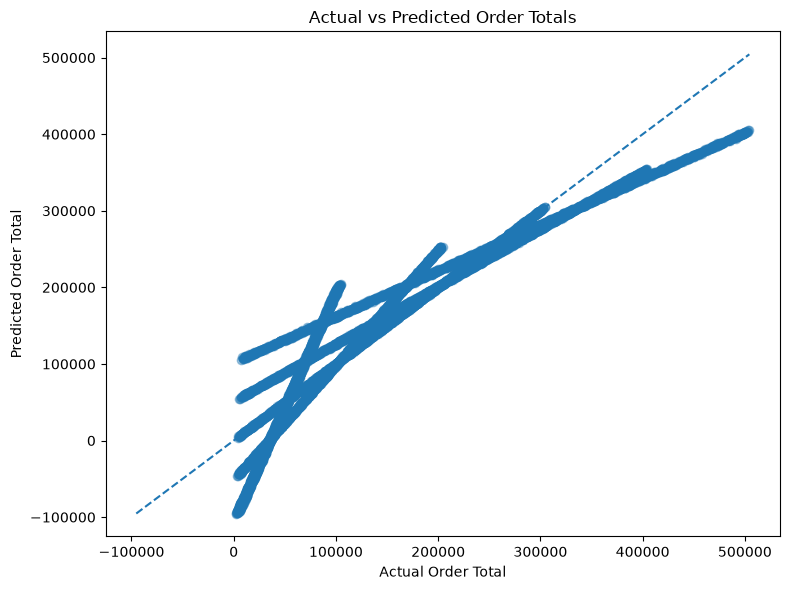

In [95]:
import matplotlib.pyplot as plt

# Actual vs Predicted Order Totals
plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test_final,
    y_reg_pred,
    alpha=0.4
)

# Reference line: perfect predictions
min_value = min(y_reg_test_final.min(), y_reg_pred.min())
max_value = max(y_reg_test_final.max(), y_reg_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Order Total")
plt.ylabel("Predicted Order Total")
plt.title("Actual vs Predicted Order Totals")
plt.tight_layout()
plt.show()

The dashed diagonal line represents perfect predictions. If the model predicted every order total correctly, all the dots would fall directly on that line.
In the plot, we can see that:
- Some predictions are relatively close to the dashed line.
- Other predictions are quite far away, particularly for some lower and higher order totals.
- The dots form several distinct diagonal patterns rather than one consistent cloud around the reference line.

So what does this tell us?
The model has learned some relationship between the input features and Order_Total, but it is making substantial errors for certain groups of orders.

### Residual Plot

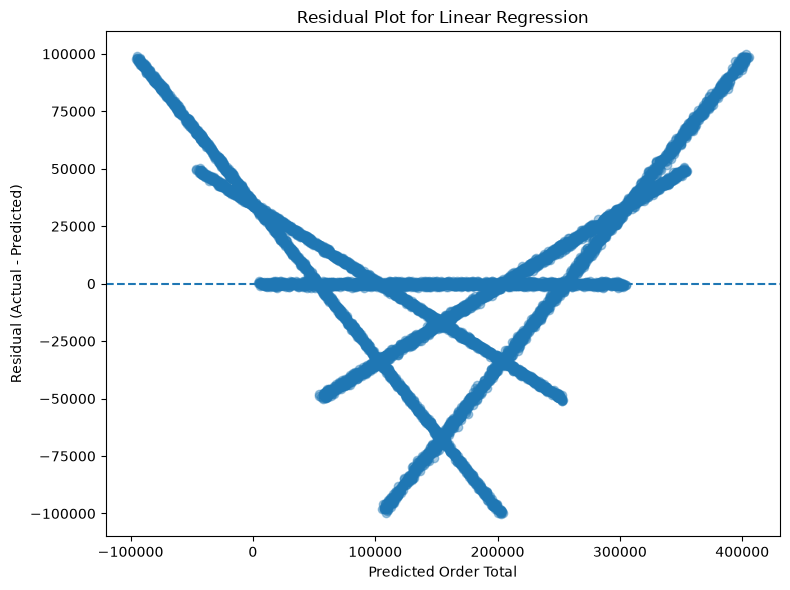

In [96]:
# Calculating residuals: actual value minus predicted value
residuals = y_reg_test_final - y_reg_pred

# Plot 2: Residuals
plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_pred,
    residuals,
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Order Total")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot for Linear Regression")
plt.tight_layout()
plt.show()

- Residual = 0: the prediction is exactly correct.
- Positive residual: the model predicted too low.
- Negative residual: the model predicted too high.

Ideally, the points should be scattered around the horizontal zero line without a strong, systematic pattern.
 My plot shows several diagonal and V-shaped patterns. This suggests the model's errors are not random. It is consistently overpredicting or underpredicting for particular ranges of values.

## 3.4 Improving the model

In [107]:
# Comparing actual and predicted values for a few test records
comparison_df = pd.DataFrame({
    "Actual_Order_Total": y_reg_test_final,
    "Predicted_Order_Total": y_reg_pred
})

comparison_df["Residual"] = (
    comparison_df["Actual_Order_Total"]
    - comparison_df["Predicted_Order_Total"]
)

comparison_df.head(10)

,Actual_Order_Total,Predicted_Order_Total,Residual
10737,191882,215967.287376,-24085.287376
9424,134825,152499.358297,-17674.358297
10340,7613,-87214.345749,94827.345749
37005,46779,18310.581291,28468.418709
23072,65288,86086.066798,-20798.066798
32784,36276,-1191.124871,37467.124871
5230,340847,305865.056698,34981.943302
46446,68759,69249.270366,-490.270366
8744,335922,302083.019772,33838.980228
31139,398085,349461.872060,48623.127940


In [108]:
# Checking the relationship between the target and its formula
formula_total = (
    (test_df["Quantity_order"] * test_df["Unit_Price_order"])
    - test_df["Discount_order"]
    + test_df["Shipping_Cost"]
)

print("Maximum difference from defined formula:")
print(
    (test_df["Order_Total"] - formula_total).abs().max()
)

Maximum difference from defined formula:
0


In [99]:
# Creating the line-total component from the predictors
test_line_total = (
    test_df["Quantity_order"]
    * test_df["Unit_Price_order"]
    - test_df["Discount_order"]
)

# Checking whether the target equals line total plus shipping
print(
    "Target formula matches:",
    (
        test_df["Order_Total"]
        == test_line_total + test_df["Shipping_Cost"]
    ).all()
)

# Inspecting the ranges of important columns
test_df[
    [
        "Quantity_order",
        "Unit_Price_order",
        "Discount_order",
        "Shipping_Cost",
        "Order_Total"
    ]
].describe().round(2)

Target formula matches: True


,Quantity_order,Unit_Price_order,Discount_order,Shipping_Cost,Order_Total
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,3.01,50554.66,9.99,2731.38,155739.40
std,1.41,28443.06,7.06,1295.34,119485.24
min,1.00,1027.00,0.00,500.00,2302.00
25%,2.00,25845.25,5.00,1609.00,59469.75
50%,3.00,51023.00,10.00,2735.00,124479.50
75%,4.00,74907.50,15.00,3845.00,230100.50
max,5.00,99995.00,20.00,5000.00,504372.00


In [100]:
# Creating a copy of the original predictor data
X_train_engineered = X_train.copy()
X_test_engineered = X_test.copy()

# Adding the interaction between quantity and unit price
X_train_engineered["Quantity_Price"] = (
    X_train_engineered["Quantity_order"]
    * X_train_engineered["Unit_Price_order"]
)

X_test_engineered["Quantity_Price"] = (
    X_test_engineered["Quantity_order"]
    * X_test_engineered["Unit_Price_order"]
)

# Checking the new feature
X_train_engineered[
    ["Quantity_order", "Unit_Price_order", "Quantity_Price"]
].head()

,Quantity_order,Unit_Price_order,Quantity_Price
25640,5,30792,153960
49675,1,63513,63513
31643,5,65937,329685
7285,4,10963,43852
42187,3,63688,191064


In [101]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Add the new feature to our numerical feature list
engineered_numeric_features = (
    regression_numeric_features + ["Quantity_Price"]
)

# Encode categorical features
encoder_engineered = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat_engineered = encoder_engineered.fit_transform(
    X_train_engineered[categorical_features]
)

X_test_cat_engineered = encoder_engineered.transform(
    X_test_engineered[categorical_features]
)

# Scale numerical features, including the new interaction feature
scaler_engineered = StandardScaler()

X_train_num_engineered = scaler_engineered.fit_transform(
    X_train_engineered[engineered_numeric_features]
)

X_test_num_engineered = scaler_engineered.transform(
    X_test_engineered[engineered_numeric_features]
)

# Combine categorical and numerical features
X_train_final_engineered = np.hstack([
    X_train_cat_engineered,
    X_train_num_engineered
])

X_test_final_engineered = np.hstack([
    X_test_cat_engineered,
    X_test_num_engineered
])

print("Training data shape:", X_train_final_engineered.shape)
print("Testing data shape:", X_test_final_engineered.shape)

Training data shape: (40000, 22)
Testing data shape: (10000, 22)


## 3.5 Training the improved Linear Regression Model

In [102]:
from sklearn.linear_model import LinearRegression

# Create the improved model
regression_model_engineered = LinearRegression()

# Train using the engineered training features
regression_model_engineered.fit(
    X_train_final_engineered,
    y_reg_train_final
)

# Predict order totals for the test data
y_reg_pred_engineered = regression_model_engineered.predict(
    X_test_final_engineered
)

print("Improved Linear Regression model trained successfully.")
print("Number of predictions:", len(y_reg_pred_engineered))

Improved Linear Regression model trained successfully.
Number of predictions: 10000


## 3.6 Evaluating the improved model's metrics

In [103]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate the evaluation metrics
mae_engineered = mean_absolute_error(
    y_reg_test_final,
    y_reg_pred_engineered
)

rmse_engineered = np.sqrt(
    mean_squared_error(
        y_reg_test_final,
        y_reg_pred_engineered
    )
)

r2_engineered = r2_score(
    y_reg_test_final,
    y_reg_pred_engineered
)

# Display the results
print(f"MAE: {mae_engineered:.2f}")
print(f"RMSE: {rmse_engineered:.2f}")
print(f"R² Score: {r2_engineered:.4f}")

MAE: 0.00
RMSE: 0.00
R² Score: 1.0000


The model now has all the components needed to reconstruct the formula. Linear Regression can learn the appropriate coefficients for these components, so a perfect score is expected.

In [104]:
print(
    "Maximum absolute prediction error:",
    np.abs(
        y_reg_test_final - y_reg_pred_engineered
    ).max()
)

Maximum absolute prediction error: 2.6193447411060333e-10


1. The original model had an R² score of 0.8875 because it lacked the quantity–price interaction.
2. Feature engineering added Quantity_Price = Quantity_order × Unit_Price_order.
3. The improved model achieved MAE = 0, RMSE = 0 and R² = 1.0000.
4. This perfect result is expected because Order_Total was constructed directly from the features. It demonstrates that the model can reproduce the formula, rather than proving that it can predict every real-world business outcome perfectly.

## 3.7 Visualisation of the improved plots

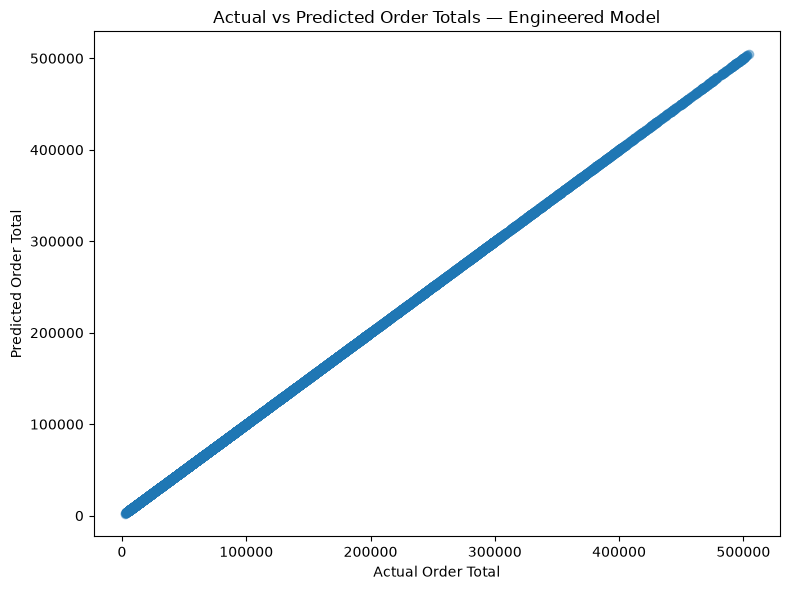

In [105]:
import matplotlib.pyplot as plt

# Actual vs Predicted Order Totals
plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test_final,
    y_reg_pred_engineered,
    alpha=0.4
)

min_value = min(
    y_reg_test_final.min(),
    y_reg_pred_engineered.min()
)

max_value = max(
    y_reg_test_final.max(),
    y_reg_pred_engineered.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Order Total")
plt.ylabel("Predicted Order Total")
plt.title("Actual vs Predicted Order Totals — Engineered Model")
plt.tight_layout()
plt.show()

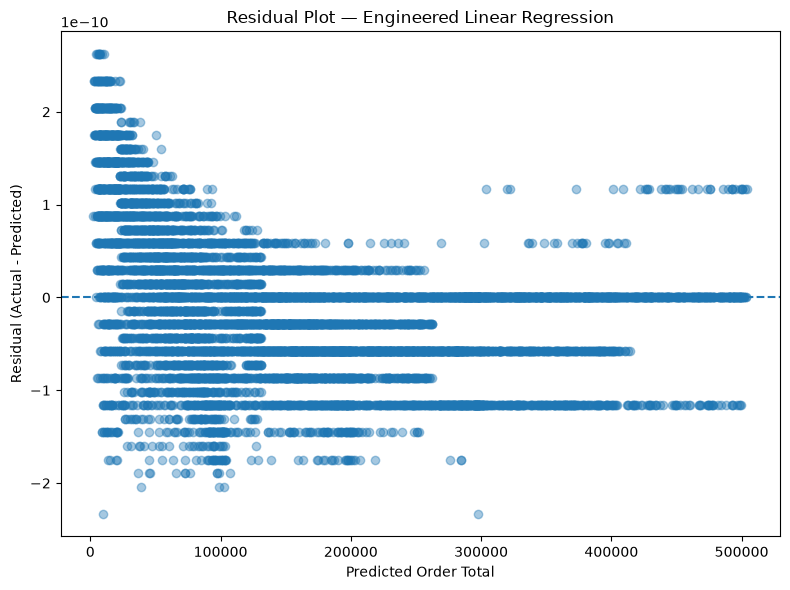

In [106]:
# Calculating residuals for the improved model
residuals_engineered = (
    y_reg_test_final - y_reg_pred_engineered
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_pred_engineered,
    residuals_engineered,
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Order Total")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot — Engineered Linear Regression")
plt.tight_layout()
plt.show()

## 3.8 Linear Regression Model Evaluation

The Linear Regression model was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination R².

The initial model achieved an MAE of 29,538.14, an RMSE of 40,079.22, and an R² score of 0.8875. To improve its performance, a new feature, `Quantity_Price`, was engineered by multiplying `Quantity_order` by `Unit_Price_order`.

After adding this feature, the improved model achieved an MAE of approximately 0, an RMSE of approximately 0, and an R² score of 1.0000 on the test set. The actual-versus-predicted plot showed near-perfect alignment with the reference line, while the residual plot showed errors extremely close to zero.

The improvement occurred because the engineered feature represented the multiplication component of the formula used to calculate `Order_Total`. Therefore, the model successfully reproduced the defined target formula. However, this perfect performance should be interpreted in context: the target was constructed directly from the input features, so the result demonstrates formula reconstruction rather than necessarily demonstrating the ability to predict uncertain real-world order totals.

# 4. Classification Model

## 4.1 Training the Model

We'll start with a baseline model using the same prepared features and the same train/test split we used earlier. This keeps the comparison fair and prevents us from accidentally using test data during training.

In [109]:

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
classification_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the training data
classification_model.fit(
    X_train_final,
    y_clf_train_final
)

# Predict Return_Flag for the test data
y_clf_pred = classification_model.predict(
    X_test_final
)

print("Logistic Regression model trained successfully.")
print("Number of predictions:", len(y_clf_pred))


Logistic Regression model trained successfully.
Number of predictions: 10000


## 4.2 Evaluating the metrics

In [110]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(
    y_clf_test_final,
    y_clf_pred
)

precision = precision_score(
    y_clf_test_final,
    y_clf_pred,
    zero_division=0
)

recall = recall_score(
    y_clf_test_final,
    y_clf_pred,
    zero_division=0
)

f1 = f1_score(
    y_clf_test_final,
    y_clf_pred,
    zero_division=0
)

# Display the results
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_clf_test_final,
        y_clf_pred,
        target_names=["Not Returned", "Returned"],
        zero_division=0
    )
)


Accuracy:  0.9512
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Classification Report:
              precision    recall  f1-score   support

Not Returned       0.95      1.00      0.97      9512
    Returned       0.00      0.00      0.00       488

    accuracy                           0.95     10000
   macro avg       0.48      0.50      0.49     10000
weighted avg       0.90      0.95      0.93     10000



Because the classes are imbalanced, Logistic Regression has learned to predict the majority class `Not Returned` for every test order. That gives it 95.12% accuracy, but it fails at the task we care about: identifying returns.
This is because of class imbalance.

## 4.3 Visualising the Confusion Matrix

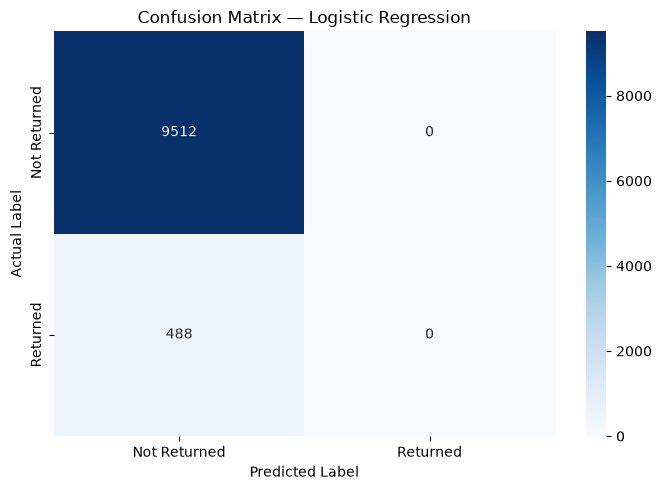

Confusion matrix:
[[9512    0]
 [ 488    0]]


In [111]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(
    y_clf_test_final,
    y_clf_pred,
    labels=[0, 1]
)

# Visualize the results
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Returned", "Returned"],
    yticklabels=["Not Returned", "Returned"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


The model predicted every order as Not Returned.

## 4.4 Improving the Model

In [112]:

# Creating a model that gives more weight to the minority class
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced", #Assigns greater weight to the less frequent class
    random_state=42
)

# Training the model
balanced_model.fit(
    X_train_final,
    y_clf_train_final
)

# Predicting on the same test set
y_clf_pred_balanced = balanced_model.predict(
    X_test_final
)

# Evaluating the balanced model
print(
    classification_report(
        y_clf_test_final,
        y_clf_pred_balanced,
        target_names=["Not Returned", "Returned"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

Not Returned       0.95      0.52      0.67      9512
    Returned       0.05      0.45      0.08       488

    accuracy                           0.52     10000
   macro avg       0.50      0.49      0.38     10000
weighted avg       0.90      0.52      0.64     10000



## 4.5 Visualising Improved Confusion Matrix

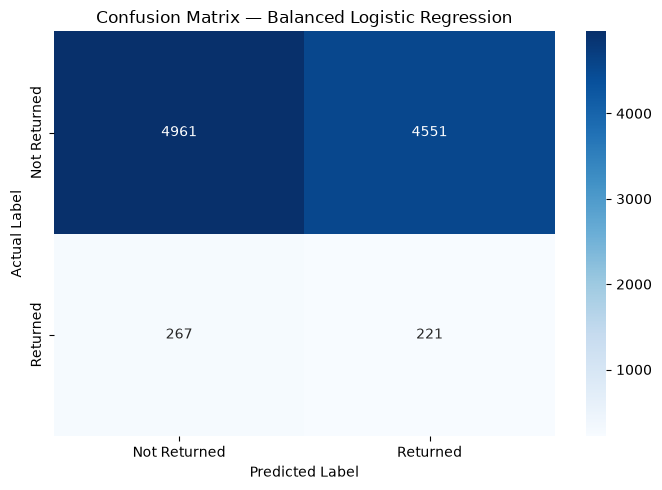

[[4961 4551]
 [ 267  221]]


In [113]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(
    y_clf_test_final,
    y_clf_pred_balanced,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Returned", "Returned"],
    yticklabels=["Not Returned", "Returned"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Balanced Logistic Regression")
plt.tight_layout()
plt.show()

print(cm_balanced)


## 4.6 Logistic Regression Evaluation

The target variable was Return_Flag, where 0 represents an order that was not returned and 1 represents an order that was returned. A Logistic Regression model was trained using the prepared training dataset and evaluated on the test dataset. The initial model achieved an accuracy of **95.12%**. However, its precision, recall, and F1-score for returned orders were all **0.00**. This indicated that the model predicted every test order as not returned.

The dataset was imbalanced: approximately **95.1%** of orders were not returned, while only **4.9%** were returned. As a result, the model could achieve high accuracy by predicting the majority class without identifying any returned orders.

To address this issue, a second Logistic Regression model was trained using `class_weight="balanced"`. This option gives greater weight to the minority class during training.

**Results of the balanced model**

The balanced model achieved an accuracy of approximately **51.82%**. Its precision for returned orders was approximately **4.63%**, recall was approximately **45.29%** and F1-score was approximately **8.44%**.

The confusion matrix was:

| | Predicted: Not Returned | Predicted: Returned |
|---|---:|---:|
| Actual: Not Returned | 4,961 | 4,551 |
| Actual: Returned | 267 | 221 |

The model correctly identified 221 returned orders but incorrectly flagged 4,551 orders that were not returned. It also missed 267 actual returns.

**Conclusion**

The initial model's high accuracy was misleading because it failed to identify returned orders. The balanced model detected more returns, but it also produced many false positives. Therefore, neither model can be practically used without further improvement. Future work could explore additional predictive features, alternative classification models and decision thresholds that balance the cost of missed returns against unnecessary return alerts.

# 5. Understanding Model Evaluation

**Regression metrics**

Mean Absolute Error (MAE) measures the average absolute difference between actual and predicted order totals. Root Mean Squared Error (RMSE) measures prediction errors while penalising larger errors more heavily. For both metrics, lower values indicate more accurate predictions. R-squared (R²) measures how much variation in the target is explained by the model relative to a mean-prediction baseline, with values closer to 1 generally indicating a better fit.

The engineered Linear Regression model achieved an MAE and RMSE of approximately zero and an R² of 1.0000. This result was expected because the engineered `Quantity_Price` feature allowed the model to reproduce the formula used to construct `Order_Total`. The results should therefore be interpreted as successful formula reconstruction rather than proof of reliable forecasting in every business situation.

**Classification metrics**

Accuracy measures the proportion of all predictions that are correct. Precision measures the proportion of predicted returns that are actual returns, while recall measures the proportion of actual returns correctly identified. The F1-score combines precision and recall into a single measure.

The initial Logistic Regression model achieved 95.12% accuracy but had zero precision, recall, and F1-score for returned orders because it predicted every order as not returned. This demonstrated why accuracy alone is insufficient when the target classes are imbalanced.

The balanced Logistic Regression model achieved approximately 4.63% precision, 45.29% recall, and an 8.44% F1-score for returned orders. It identified more returns but also produced many false positives. Its confusion matrix contained 221 true positives, 4,961 true negatives, 4,551 false positives, and 267 false negatives.

**Business interpretation**

ShopSmart should select evaluation metrics according to the business objective. For order-total estimation, MAE and RMSE help quantify prediction errors, while R² indicates how well the model explains variation in order totals. For return detection, precision and recall are particularly important because false alarms and missed returns can have different operational costs. The current classification results indicate that further model improvement is needed before the predictions should be relied upon for business decisions.

# 6. Feature Importance

## 6.1 Feature Importance for Linear Regression

In [115]:
import pandas as pd
import matplotlib.pyplot as plt

# Getting the names created by one-hot encoding
categorical_feature_names = encoder_final.get_feature_names_out(
    categorical_features
)

# Combining categorical and engineered numerical feature names
all_feature_names = list(categorical_feature_names) + (
    engineered_numeric_features
)

# Extracting the trained model's coefficients
regression_coefficients = pd.DataFrame({
    "Feature": all_feature_names,
    "Coefficient": regression_model_engineered.coef_
})

# Sorting by absolute coefficient size
regression_coefficients["Absolute_Importance"] = (
    regression_coefficients["Coefficient"].abs()
)

regression_coefficients = regression_coefficients.sort_values(
    by="Absolute_Importance",
    ascending=False
)

regression_coefficients.head(15)

,Feature,Coefficient,Absolute_Importance
21,Quantity_Price,1.189887e+05,1.189887e+05
20,Shipping_Cost,1.296366e+03,1.296366e+03
19,Discount_order,-7.093228e+00,7.093228e+00
18,Unit_Price_order,1.274158e-10,1.274158e-10
17,Quantity_order,1.126271e-10,1.126271e-10
5,Payment_Method_Transfer,6.771680e-11,6.771680e-11
15,Region_South,2.965035e-11,2.965035e-11
6,Sales_Channel_In-Store,2.798321e-11,2.798321e-11
14,Region_North,-2.441964e-11,2.441964e-11
2,Customer_Segment_Silver,2.078351e-11,2.078351e-11


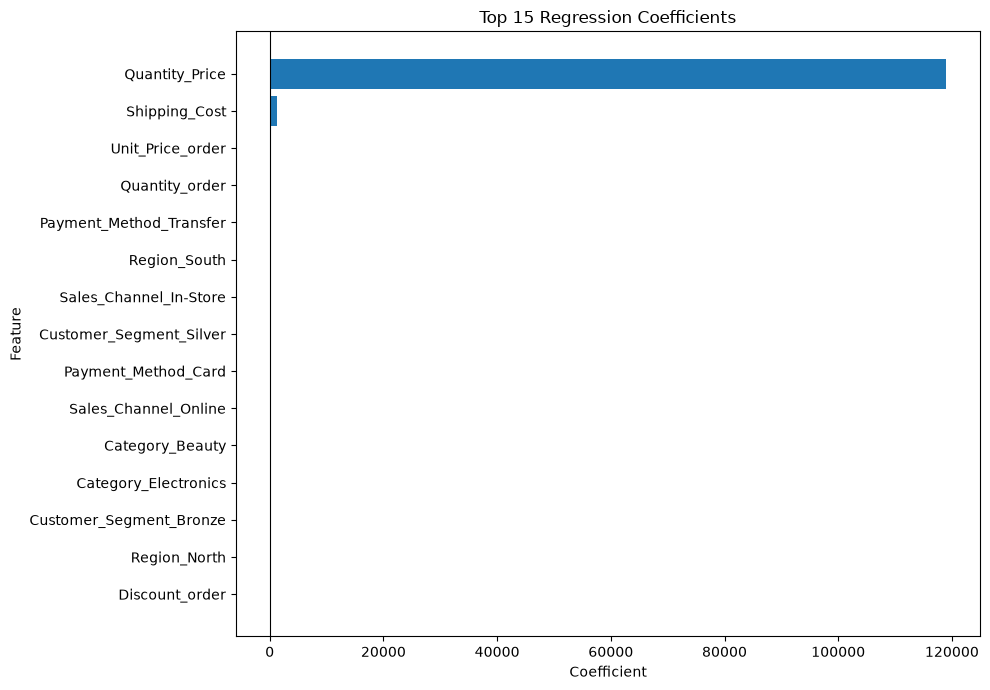

In [116]:
top_features = regression_coefficients.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 15 Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 6.2 feature Importance for Logistic Regression

In [118]:
classification_feature_names = list(
    encoder_final.get_feature_names_out(categorical_features)
) + classification_numeric_features

print("Feature names:", len(classification_feature_names))
print("Model coefficients:", len(balanced_model.coef_[0]))

Feature names: 21
Model coefficients: 21


In [119]:
classification_coefficients = pd.DataFrame({
    "Feature": classification_feature_names,
    "Coefficient": balanced_model.coef_[0]
})

classification_coefficients["Absolute_Importance"] = (
    classification_coefficients["Coefficient"].abs()
)

classification_coefficients = classification_coefficients.sort_values(
    by="Absolute_Importance",
    ascending=False
)

classification_coefficients.head(15)

,Feature,Coefficient,Absolute_Importance
13,Region_East,0.084940,0.084940
12,Category_Home,0.078942,0.078942
14,Region_North,-0.073022,0.073022
9,Category_Electronics,-0.046630,0.046630
17,Quantity_order,0.040646,0.040646
20,Shipping_Cost,-0.036952,0.036952
0,Customer_Segment_Bronze,0.036353,0.036353
7,Sales_Channel_Online,-0.033601,0.033601
6,Sales_Channel_In-Store,0.030122,0.030122
1,Customer_Segment_Gold,-0.026843,0.026843


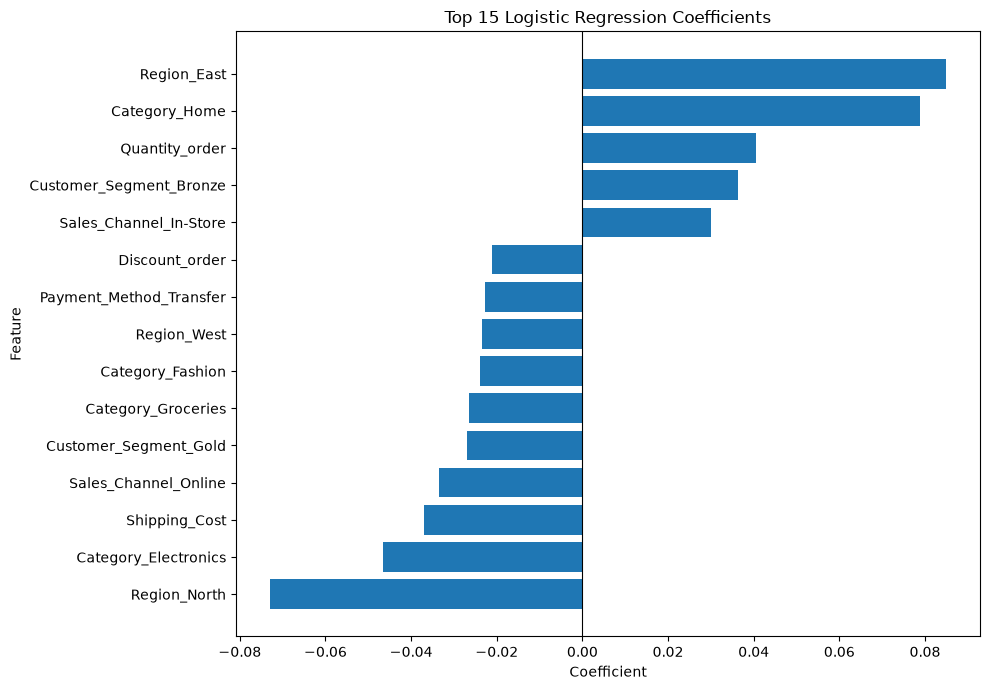

In [120]:
top_classification_features = (
    classification_coefficients.head(15)
    .sort_values(by="Coefficient")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_classification_features["Feature"],
    top_classification_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 6.3 Feature Importance Summary

### Linear Regression Feature Importance

The regression coefficient analysis identified `Quantity_Price` as the dominant feature for predicting `Order_Total`, followed by `Shipping_Cost`. The remaining features had comparatively small coefficients. This result is consistent with the way the target variable was constructed from the order's quantity, unit price, discount, and shipping cost. The model's perfect R² score therefore mainly reflects its ability to reconstruct the target formula, rather than demonstrating reliable forecasting of unknown order totals.

### Logistic Regression Feature Importance

The logistic regression coefficient analysis identified `Region_East`, `Category_Home`, and `Quantity_order` among the features with the largest positive coefficients. Features including `Region_North`, `Category_Electronics`, and `Shipping_Cost` had relatively large negative coefficients. Positive coefficients increase the model's estimated tendency to classify an order as returned, while negative coefficients decrease it, holding other features constant.

These coefficients describe associations learned by the model and should not be interpreted as evidence of causation. Furthermore, the classification model had low precision for returned orders, meaning that many orders predicted as returns were not actually returned. Consequently, these findings should be treated as exploratory and validated further before informing business decisions.

# 7. Business Questions

## 1. Which variables best predict customer spending?

In [122]:
# Creating a table of regression coefficients
spending_features = pd.DataFrame({
    "Feature": all_feature_names,
    "Coefficient": regression_model_engineered.coef_
})

spending_features["Absolute_Importance"] = (
    spending_features["Coefficient"].abs()
)

spending_features = spending_features.sort_values(
    by="Absolute_Importance",
    ascending=False
)

spending_features.head(10)

,Feature,Coefficient,Absolute_Importance
21,Quantity_Price,1.189887e+05,1.189887e+05
20,Shipping_Cost,1.296366e+03,1.296366e+03
19,Discount_order,-7.093228e+00,7.093228e+00
18,Unit_Price_order,1.274158e-10,1.274158e-10
17,Quantity_order,1.126271e-10,1.126271e-10
5,Payment_Method_Transfer,6.771680e-11,6.771680e-11
15,Region_South,2.965035e-11,2.965035e-11
6,Sales_Channel_In-Store,2.798321e-11,2.798321e-11
14,Region_North,-2.441964e-11,2.441964e-11
2,Customer_Segment_Silver,2.078351e-11,2.078351e-11


The regression coefficient analysis identified `Quantity_Price` as the dominant feature in predicting `Order_Total`, with a coefficient of approximately 118,988.70. `Shipping_Cost` had the next-largest positive coefficient, approximately 1,296.37, while `Discount_order` had a negative coefficient of approximately -7.09. The remaining features had coefficients close to zero.

These results are consistent with the construction of the target variable, because `Quantity_Price` is calculated by multiplying order quantity by unit price, and `Order_Total` is derived from line total and shipping cost. Consequently, the model primarily reconstructs the order-value calculation rather than independently identifying customer characteristics associated with higher spending. Future models should use customer-level features such as customer segment, purchase frequency, historical spending, membership level and customer tenure to predict spending on a future order. 

## 2. Which variables influence product returns?

In [124]:
classification_coefficients.head(10)

,Feature,Coefficient,Absolute_Importance
13,Region_East,0.084940,0.084940
12,Category_Home,0.078942,0.078942
14,Region_North,-0.073022,0.073022
9,Category_Electronics,-0.046630,0.046630
17,Quantity_order,0.040646,0.040646
20,Shipping_Cost,-0.036952,0.036952
0,Customer_Segment_Bronze,0.036353,0.036353
7,Sales_Channel_Online,-0.033601,0.033601
6,Sales_Channel_In-Store,0.030122,0.030122
1,Customer_Segment_Gold,-0.026843,0.026843


The balanced Logistic Regression model identified region, product category, order quantity, shipping cost, customer segment, and sales channel as features associated with return predictions. `Region_East` had the largest positive coefficient (approximately 0.0849), followed by `Category_Home` (0.0789). In contrast, `Region_North` had the largest negative coefficient (-0.0730), followed by `Category_Electronics` (-0.0466).

Positive coefficients indicate that a feature increases the model's estimated tendency to classify an order as returned, while negative coefficients indicate the opposite, holding other features constant. These results suggest that return behaviour may vary across regions, categories, and customer or transaction characteristics.

However, the coefficients do not establish causation. The balanced model achieved approximately 45.3% recall but only 4.6% precision for returned orders, meaning that many orders predicted as returns were not actually returned. ShopSmart should therefore validate these patterns using additional data before using them to guide return-prevention policies.

## 3. Which products are easiest to predict?

In [126]:
product_predictability = (
    master_df.groupby("Product_Name")["Line_Total"]
    .agg(
        Average_Line_Total="mean",
        Standard_Deviation="std",
        Number_of_Orders="count"
    )
    .reset_index()
)

product_predictability = product_predictability.sort_values(
    "Standard_Deviation",
    ascending=True
)

product_predictability.head(10)

,Product_Name,Average_Line_Total,Standard_Deviation,Number_of_Orders
498,Home Item 95,126093.806122,92369.346161,98
365,Groceries Item 334,136017.645833,93918.581264,96
342,Groceries Item 200,126827.161290,94577.591461,93
49,Beauty Item 264,124721.328767,95723.795141,73
169,Electronics Item 323,135400.927835,98904.444853,97
360,Groceries Item 312,142739.830645,99541.250247,124
471,Home Item 412,121690.160920,100411.240638,87
209,Electronics Item 64,123286.701923,100437.303569,104
352,Groceries Item 252,124688.742857,100986.519307,105
46,Beauty Item 253,142746.410526,101285.964587,95


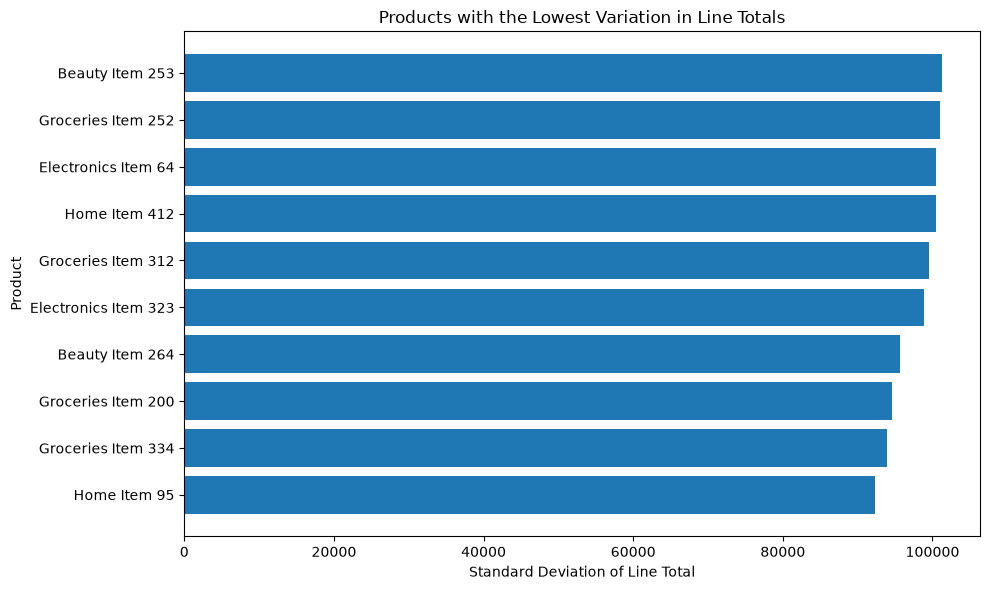

In [127]:
top_10_consistent = product_predictability.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_10_consistent["Product_Name"],
    top_10_consistent["Standard_Deviation"]
)
plt.title("Products with the Lowest Variation in Line Totals")
plt.xlabel("Standard Deviation of Line Total")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Among the ten products with the lowest standard deviations, Home Item 95 had the lowest value, approximately 92,369.35, based on 98 orders. It was followed by Groceries Item 334, with a standard deviation of approximately 93,918.58 across 96 orders.

These results suggest that Home Item 95 had the least variation in observed line totals among the products listed. However, this analysis measures variability rather than actual model accuracy. Therefore, these products should be considered candidates for further investigation, not confirmed as the easiest products to predict.

## 4. Which customer groups generate the highest order values?

In [128]:
# Calculating the total value for each order
order_values = (
    master_df.groupby(
        ["Order_ID", "Customer_ID", "Customer_Segment"],
        as_index=False
    )["Line_Total"]
    .sum()
    .rename(columns={"Line_Total": "Order_Value"})
)

# Comparing order values across customer segments
segment_spending = (
    order_values.groupby("Customer_Segment")["Order_Value"]
    .agg(
        Average_Order_Value="mean",
        Median_Order_Value="median",
        Number_of_Orders="count"
    )
    .sort_values("Average_Order_Value", ascending=False)
    .reset_index()
)

segment_spending

,Customer_Segment,Average_Order_Value,Median_Order_Value,Number_of_Orders
0,Silver,151835.915698,118870.0,16773
1,Gold,151354.190024,117805.0,16961
2,Bronze,151321.028833,119671.0,16266


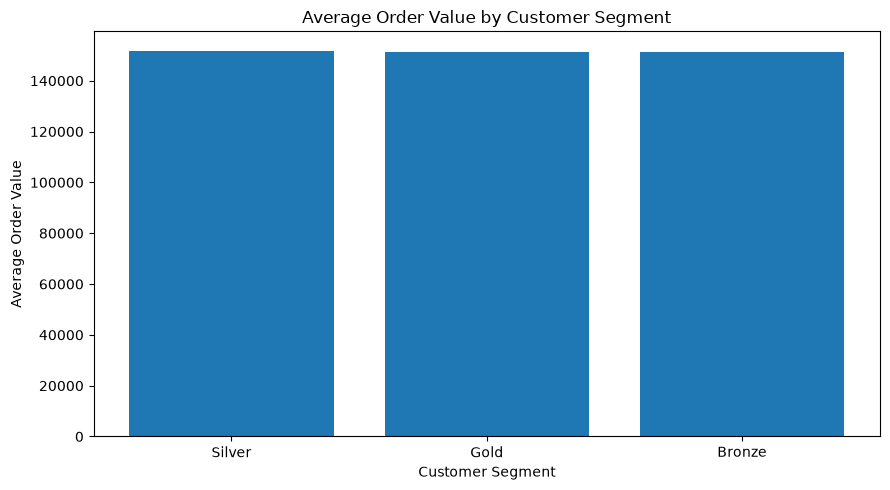

In [129]:
plt.figure(figsize=(9, 5))

plt.bar(
    segment_spending["Customer_Segment"],
    segment_spending["Average_Order_Value"]
)

plt.title("Average Order Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Order Value")
plt.tight_layout()
plt.show()

Silver customers recorded the highest average order value of approximately 151,835.92, followed by Gold customers at 151,354.19 and Bronze customers at 151,321.03.

Gold customers generated the highest number of orders (16,961), while Bronze customers had the highest median order value (119,671). However, the differences in average order value between the three segments were relatively small. Therefore, the results suggest that spending levels are broadly similar across the segments rather than showing a clear spending advantage for one group.

ShopSmart could use these findings to investigate customer purchasing patterns and develop targeted marketing strategies. Further analysis of purchase frequency, customer lifetime value, and statistical differences between segments would help determine whether these observed differences are meaningful.

*Order values were calculated by summing `Line_Total` for each order, excluding shipping costs.*

## 5. Which stores perform best?

In [130]:

# Calculating the value of each order at each store
order_values_by_store = (
    master_df.groupby(
        ["Order_ID", "Store_ID", "Store_Name"],
        as_index=False
    )["Line_Total"]
    .sum()
    .rename(columns={"Line_Total": "Order_Value"})
)

# Summarising performance for each store
store_performance = (
    order_values_by_store.groupby(
        ["Store_ID", "Store_Name"]
    )["Order_Value"]
    .agg(
        Total_Order_Value="sum",
        Average_Order_Value="mean",
        Number_of_Orders="count"
    )
    .reset_index()
    .sort_values(
        "Total_Order_Value",
        ascending=False
    )
)

store_performance.head(10)


,Store_ID,Store_Name,Total_Order_Value,Average_Order_Value,Number_of_Orders
14,STR015,ShopSmart Lagos,311890852,151109.908915,2064
20,STR021,ShopSmart Lagos,311156234,153278.933005,2030
16,STR017,ShopSmart Abuja,309777616,153965.017893,2012
9,STR010,ShopSmart Abuja,309168850,150667.080897,2052
17,STR018,ShopSmart Ibadan,308710089,151476.981845,2038
7,STR008,ShopSmart Port Harcourt,308605840,152850.837048,2019
11,STR012,ShopSmart Abeokuta,307702799,153467.730175,2005
8,STR009,ShopSmart Ibadan,307425710,152568.590571,2015
6,STR007,ShopSmart Ibadan,306039203,154721.538423,1978
2,STR003,ShopSmart Lagos,305885340,155271.746193,1970


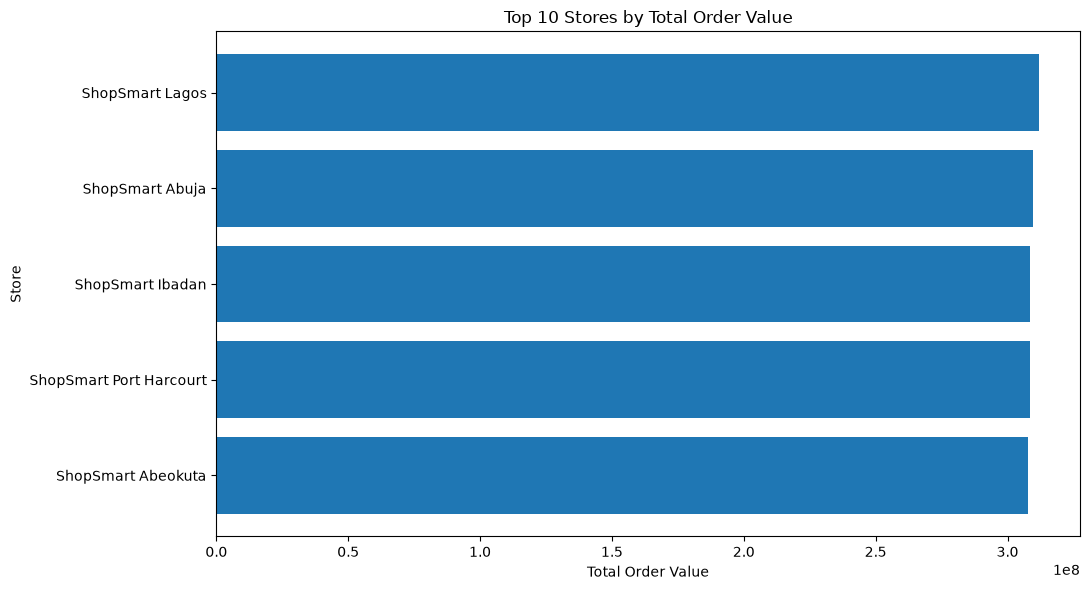

In [131]:

top_10_stores = store_performance.head(10)

plt.figure(figsize=(11, 6))

plt.barh(
    top_10_stores["Store_Name"],
    top_10_stores["Total_Order_Value"]
)

plt.title("Top 10 Stores by Total Order Value")
plt.xlabel("Total Order Value")
plt.ylabel("Store")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


Store performance was evaluated using total order value, average order value, and number of orders. ShopSmart Lagos (STR015) recorded the highest total order value of 311,890,852 and handled 2,064 orders, the highest order count among the ten stores displayed. In contrast, ShopSmart Lagos (STR003) recorded the highest average order value among these stores, at approximately 155,271.75 per order.

The results demonstrate that store performance depends on the measure used. STR015 leads in total order value and order volume, while STR003 leads in average order value. The total order values of the ten leading stores are relatively close, suggesting similar overall order-value performance among these stores.

ShopSmart could use these findings to investigate the practices of high-performing stores and identify opportunities to improve order volume and average order value at other locations. However, total order value alone does not establish profitability or operational efficiency. Further analysis incorporating operating costs, profit margins, customer traffic, and store size would provide a more complete performance assessment.

## 6. How could the business use these predictive models?

In [133]:

business_uses = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression"
    ],
    "Business_Application": [
        "Order value estimation and sales planning",
        "Return risk screening and investigation"
    ]
})

business_uses


,Model,Business_Application
0,Linear Regression,Order value estimation and sales planning
1,Logistic Regression,Return risk screening and investigation


ShopSmart Retail Ltd. could use predictive models to support planning, customer service, and operational decision-making.

**1. Order value estimation:** The Linear Regression model could help estimate order values and support sales planning. If developed using information available before an order is completed, a reliable model could assist with revenue forecasting, budgeting and inventory planning. However, the current model achieved near-perfect performance partly because the engineered `Quantity_Price` feature reconstructs the formula used to calculate the target. Further testing with genuinely predictive features is therefore necessary before using it for future forecasting.

**2. Return risk identification:** The Logistic Regression model could help identify orders that may be more likely to be returned. Customer segment, product category, region, sales channel, quantity, and shipping cost showed associations with the model's return predictions. ShopSmart could investigate these patterns to identify possible service or product issues. However, the balanced model had a recall of approximately 45.3% and precision of approximately 4.6%, meaning that it detected some returned orders but generated many false-positive alerts. Its predictions should be treated as preliminary risk indicators rather than reliable return decisions.

**3. Better resource allocation:** Once the models have been improved and validated, their predictions could support sales planning, customer support prioritisation, and investigations into return patterns across stores, products, and customer segments.

## 7. What limitations do the models have?

The ShopSmart predictive models have several limitations that should be considered before they are used for business decisions.

**1. Target leakage and formula reconstruction:** The Linear Regression model achieved near-zero MAE and RMSE and an R² of 1.00 after the `Quantity_Price` feature was introduced. Since the target was constructed using quantity multiplied by unit price, minus discount, plus shipping cost, this feature allows the model to reconstruct the target formula. Consequently, the excellent evaluation scores do not demonstrate that the model can independently forecast future customer spending.

**2. Class imbalance:** Returned orders accounted for approximately 4.9% of the dataset. The baseline Logistic Regression model achieved 95.12% accuracy by predicting all orders as not returned but it failed to identify returned orders. This demonstrates that accuracy alone is not an adequate evaluation metric for an imbalanced classification problem.

**3. Low precision in return predictions:** The balanced Logistic Regression model achieved approximately 45.3% recall and 4.6% precision for returned orders. Although it detected some returned orders, it also generated many false positives. This limits its usefulness for operational decisions without further improvement.

**4. Limited input features:** The models do not include potentially useful information such as detailed customer purchase history, product quality, delivery delays, customer satisfaction, or return reasons. The absence of these variables may limit predictive performance.

**5. Model simplicity:** Linear Regression and Logistic Regression may not capture complex nonlinear relationships or interactions among customer, product and transaction characteristics.

**6. Generalisation over time:** The models were evaluated using a random train-test split. Their performance on future orders may differ if purchasing patterns, product offerings or business conditions change.

In conclusion, the models are useful as initial learning prototypes, but their results should be interpreted cautiously. ShopSmart should improve feature selection, address class imbalance, test models on future data and evaluate business costs before considering operational deployment.

## 8. What additional data would improve our predictions?

In [134]:

additional_data = pd.DataFrame({
    "Additional_Data": [
        "Customer purchase history",
        "Product quality and return reasons",
        "Delivery time and delays",
        "Promotions and discounts",
        "Inventory and stockouts",
        "Store costs and profit margins"
    ],
    "Potential_Benefit": [
        "Improve spending and return-risk predictions",
        "Identify factors associated with returns",
        "Investigate delivery-related returns",
        "Understand purchasing and order-value patterns",
        "Improve demand planning",
        "Evaluate store profitability"
    ]
})

additional_data


,Additional_Data,Potential_Benefit
0,Customer purchase history,Improve spending and return-risk predictions
1,Product quality and return reasons,Identify factors associated with returns
2,Delivery time and delays,Investigate delivery-related returns
3,Promotions and discounts,Understand purchasing and order-value patterns
4,Inventory and stockouts,Improve demand planning
5,Store costs and profit margins,Evaluate store profitability


The predictive performance of ShopSmart's models could potentially be improved by collecting additional customer, product, delivery and operational data.

**1. Customer purchase history:** Previous order values, purchase frequency, customer tenure and past return behaviour could help the business understand customer spending patterns and identify customers who may be more likely to return products.

**2. Product quality and return information:** Product defect records, customer ratings, reviews and detailed return reasons could help the classification model identify factors associated with product returns.

**3. Delivery information:** Delivery duration, late deliveries, damaged items, and fulfilment issues could reveal relationships between delivery experiences and return behaviour.

**4. Promotions and marketing data:** Information about coupons, discounts, campaigns, and promotional periods could help explain changes in order values and purchasing behaviour.

**5. Inventory and demand data:** Historical stock levels, stockouts, and product availability could support better demand forecasting and help the business understand sales patterns.

**6. Store performance and cost data:** Operating expenses, staffing costs, profit margins, customer traffic, and store size could help ShopSmart assess store profitability and operational efficiency rather than relying solely on total order value.

Overall, richer and more relevant data could help ShopSmart develop more informative predictive models. However, collecting additional data does not automatically guarantee better performance. The new variables should be checked for quality, relevance, and availability at prediction time, and their contribution should be evaluated using unseen data.

# 8. Model Persistence

In [137]:

import joblib
from pathlib import Path

# Creating the models folder if it doesn't exist
models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# Saving the trained models
joblib.dump(
    regression_model_engineered,
    models_dir / "linear_regression.pkl"
)

joblib.dump(
    balanced_model,
    models_dir / "logistic_regression.pkl"
)

# Saving the encoders
joblib.dump(
    encoder_engineered,
    models_dir / "encoder.pkl"
)

# Saving both scalers in one file
joblib.dump(
    {
        "regression_scaler": scaler_engineered,
        "classification_scaler": scaler_final
    },
    models_dir / "scaler.pkl"
)

print("Models and preprocessing objects saved successfully.")


Models and preprocessing objects saved successfully.


In [138]:

for file in sorted(models_dir.glob("*.pkl")):
    print(file, "-", "Saved" if file.exists() else "Missing")


models\encoder.pkl - Saved
models\linear_regression.pkl - Saved
models\logistic_regression.pkl - Saved
models\scaler.pkl - Saved


Verifying that the saved models can be loaded back and used to make predictions which is the final important step.

In [139]:

import joblib
import numpy as np
from pathlib import Path

models_dir = Path("models")

# Load the saved models
loaded_regression_model = joblib.load(
    models_dir / "linear_regression.pkl"
)

loaded_logistic_model = joblib.load(
    models_dir / "logistic_regression.pkl"
)

# Load the saved preprocessing objects
loaded_encoder = joblib.load(
    models_dir / "encoder.pkl"
)

loaded_scalers = joblib.load(
    models_dir / "scaler.pkl"
)

# Use the loaded models to predict on prepared test data
regression_predictions_loaded = loaded_regression_model.predict(
    X_test_final_engineered
)

classification_predictions_loaded = loaded_logistic_model.predict(
    X_test_final
)

print("Regression predictions:", regression_predictions_loaded[:5])
print("Classification predictions:", classification_predictions_loaded[:5])

print("\nNumber of regression predictions:",
      len(regression_predictions_loaded))

print("Number of classification predictions:",
      len(classification_predictions_loaded))


Regression predictions: [191882. 134825.   7613.  46779.  65288.]
Classification predictions: [1 1 0 0 0]

Number of regression predictions: 10000
Number of classification predictions: 10000


Verifying prediction consistency

In [140]:

# Comparing loaded-model predictions with original predictions
regression_match = np.allclose(
    regression_model_engineered.predict(X_test_final_engineered),
    regression_predictions_loaded
)

classification_match = np.array_equal(
    balanced_model.predict(X_test_final),
    classification_predictions_loaded
)

print("Regression predictions match:", regression_match)
print("Classification predictions match:", classification_match)


Regression predictions match: True
Classification predictions match: True


## Preparing my saved preprocessed objects for `predict.py`

In [141]:
models_dir = Path("models")

# Saving both fitted encoders
joblib.dump(
    {
        "regression_encoder": encoder_engineered,
        "classification_encoder": encoder_final
    },
    models_dir / "encoder.pkl"
)

# Saving both fitted scalers
joblib.dump(
    {
        "regression_scaler": scaler_engineered,
        "classification_scaler": scaler_final
    },
    models_dir / "scaler.pkl"
)

print("Both encoders and scalers saved successfully.")


Both encoders and scalers saved successfully.


In [143]:
master_df.columns

Index(['Order_ID', 'Customer_ID', 'Product_ID', 'Store_ID', 'Order_Date',
       'Quantity_order', 'Unit_Price_order', 'Discount_order', 'Shipping_Cost',
       'Payment_Method', 'Sales_Channel', 'Order_Status', 'Order_Item_ID',
       'Line_Total', 'Order_Total', 'Return_Flag', 'First_Name', 'Last_Name',
       'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date',
       'Customer_Segment', 'Product_Name', 'Category', 'Sub_Category', 'Brand',
       'Cost_Price', 'Selling_Price', 'Store_Name', 'Region', 'State_store',
       'City_store', 'Opening_Date'],
      dtype='str')

In [149]:
master_df['Shipping_Cost'].describe()

count    50000.000000
mean      2747.708600
std       1296.187071
min        500.000000
25%       1628.000000
50%       2751.000000
75%       3866.000000
max       5000.000000
Name: Shipping_Cost, dtype: float64

## How to run the Prediction Script `predict.py`

Follow these steps to generate predictions using the saved ShopSmart machine learning models.

1. Open the VS Code terminal from the project root directory.
2. Run the following command:

   ```bash
   python scripts/predict.py
   ```

3. Enter the preferred **Quantity** (e.g., between 1 and 5).
4. Enter the preferred **Unit Price** (e.g., between 1,000 and 100,000).
5. Enter the preferred **Discount Amount** (e.g., between 0 and 100).
6. Enter the preferred **Shipping Cost** (e.g., between 500 and 5,000).
7. Follow the subsequent prompts by entering the number corresponding to your preferred customer segment, payment method, sales channel, product category, and region.
8. Once all inputs have been provided, the script will display the **Predicted Order Value** and **Return Probability** in the terminal.
